# 07b. Advanced Data Issues: Class Imbalance, Data Leakage and Data Drift

The model of notebook 07a works, but a good test score can hide three kinds of problem. This notebook examines each on purpose:

1. **Class imbalance.** The main target (at risk, 44%) is nearly balanced, so imbalance matters for the rarer outcomes (Withdrawn 19%, Distinction 11%). Which fixes help, and what do they break?
2. **Data leakage.** Leaky features are built *deliberately* to measure how much they inflate results, and to show which leaks a train/test split can and cannot detect.
3. **Data drift.** How different is 2014 from 2013 in its inputs, its labels and its relationships, and how would we notice in practice?

**Rules.** Strategy choices in the imbalance section are made by cross-validation on 2013 (grouped by student); the 2014 results are reported as confirmation and are not used to choose. Resampling, scaling and thresholds are always fitted inside the training part. SMOTE is implemented by hand (about 15 lines) so that no extra package has to be installed.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import GroupKFold, StratifiedKFold, KFold
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_recall_curve, brier_score_loss
from sklearn.inspection import permutation_importance

sys.path.insert(0, "../src")
import items as it

RANDOM_STATE = 42
RAW, PROC, OUT = Path("../data/raw"), Path("../data/processed"), Path("../outputs")
FIG = OUT / "figures"
KEY = it.KEY

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
def savefig(fig, name): fig.savefig(FIG / name, dpi=150, bbox_inches="tight")

feat = pd.read_csv(PROC / "oulad_features_day28.csv")
fspec = json.loads((OUT / "feature_groups.json").read_text())
mspec = json.loads((OUT / "final_model_spec.json").read_text())
train = feat[feat.split == "train"].reset_index(drop=True)
test = feat[feat.split == "test"].reset_index(drop=True)
SEL_NUM, SEL_CAT = fspec["selected_numeric"], fspec["selected_categorical"]
HGB_P = mspec["hgb_params"]
y_tr, y_te = train.target_at_risk.values, test.target_at_risk.values
folds = list(GroupKFold(n_splits=5).split(train, groups=train.id_student))

def hgb(**kw):
    p = dict(max_depth=HGB_P["depth"], learning_rate=HGB_P["lr"], max_iter=HGB_P["iters"], l2_regularization=HGB_P["l2"], min_samples_leaf=HGB_P["leaf"], random_state=RANDOM_STATE)
    p.update(kw); return HistGradientBoostingClassifier(**p)
def pipe_hgb(num, cat=(), **kw):
    parts = [("num", "passthrough", list(num))] + ([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))] if cat else [])
    return Pipeline([("pre", ColumnTransformer(parts)), ("m", hgb(**kw))])
print(f"train {len(train):,} | test {len(test):,} | primary model: gradient boosting {HGB_P}")

train 11,818 | test 15,735 | primary model: gradient boosting {'depth': 4, 'lr': 0.03, 'iters': 300, 'l2': 3.0, 'leaf': 40}


## 1. Class imbalance

### 1.1 How imbalanced are the targets?

In [2]:
tg = {"At risk (main target)": (train.target_at_risk.values == 1, test.target_at_risk.values == 1),
      "Withdrawn": (train.target_final_result.values == "Withdrawn", test.target_final_result.values == "Withdrawn"),
      "Fail": (train.target_final_result.values == "Fail", test.target_final_result.values == "Fail"),
      "Distinction": (train.target_final_result.values == "Distinction", test.target_final_result.values == "Distinction")}
prev = pd.DataFrame({k: {"share 2013": a.mean(), "share 2014": b.mean(), "imbalance ratio (majority : minority) 2013": (1 - a.mean()) / a.mean()} for k, (a, b) in tg.items()}).T
display(prev)
print("Smallest per-module at-risk share in 2014 (a hidden imbalance inside the balanced target):", test.groupby("code_module").target_at_risk.mean().round(3).to_dict())

,share 2013,share 2014,imbalance ratio (majority : minority) 2013
At risk (main target),0.444,0.440,1.252
Withdrawn,0.170,0.198,4.868
Fail,0.274,0.242,2.654
Distinction,0.091,0.124,9.983


Smallest per-module at-risk share in 2014 (a hidden imbalance inside the balanced target): {'AAA': 0.273, 'BBB': 0.388, 'CCC': 0.524, 'DDD': 0.49, 'EEE': 0.36, 'FFF': 0.44, 'GGG': 0.391}


**Observed.** The main target is nearly balanced (1.25 : 1), but the outcomes behind it are not: Withdrawn is 17.0% of the students in 2013 (4.9 : 1), Fail 27.4% and Distinction 9.1% (10 : 1). These rare outcomes also **drifted**: in 2014 Withdrawn is 19.8% and Distinction 12.4%. Inside the balanced target there is a second imbalance: the at-risk share runs from 27% (AAA) to 52% (CCC).

### 1.2 Strategies compared (all fitted inside the training folds)

- **None**, **class weights** (balanced), **random oversampling** and **random undersampling** (both to a 1:1 ratio), **SMOTE** (synthetic minority points interpolated between nearest minority neighbours, 1:1) and **threshold tuning** (choose the cut-off that maximises F1 on out-of-fold predictions; no resampling).
- The study uses the 17 numeric selected features (median imputation and standardisation fitted on each training fold), so that SMOTE can interpolate in a meaningful space. Gradient boosting with the tuned settings is the classifier.

In [3]:
def smote(X, y, k=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed); Xm = X[y == 1]; n_new = int((y == 0).sum() - (y == 1).sum())
    if n_new <= 0 or len(Xm) <= k: return X, y
    nn = NearestNeighbors(n_neighbors=k + 1).fit(Xm); neigh = nn.kneighbors(Xm, return_distance=False)[:, 1:]
    base = rng.randint(0, len(Xm), n_new); nb = neigh[base, rng.randint(0, k, n_new)]; lam = rng.rand(n_new, 1)
    Xs = Xm[base] + lam * (Xm[nb] - Xm[base])
    return np.vstack([X, Xs]), np.concatenate([y, np.ones(n_new, int)])

def resample(strategy, X, y, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed); pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    if strategy == "oversample":
        idx = np.concatenate([neg, pos, rng.choice(pos, len(neg) - len(pos), replace=True)]); return X[idx], y[idx]
    if strategy == "undersample":
        idx = np.concatenate([pos, rng.choice(neg, len(pos), replace=False)]); return X[idx], y[idx]
    if strategy == "smote": return smote(X, y, seed=seed)
    return X, y

STRATS = ["none", "class weights", "oversample", "undersample", "smote"]
def fit_predict(strategy, Xtr, ytr, Xva):
    imp = SimpleImputer(strategy="median").fit(Xtr); sc = StandardScaler().fit(imp.transform(Xtr))
    A, B = sc.transform(imp.transform(Xtr)), sc.transform(imp.transform(Xva))
    A, ytr2 = resample(strategy, A, np.asarray(ytr).astype(int))
    m = hgb(class_weight="balanced") if strategy == "class weights" else hgb()
    return m.fit(A, ytr2).predict_proba(B)[:, 1]

def best_f1_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p); f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12); i = np.nanargmax(f1[:-1]); return float(th[i])

Xtr_all, Xte_all = train[SEL_NUM].values, test[SEL_NUM].values
rows = []
for tname in ["Withdrawn", "Distinction"]:
    ytr_t, yte_t = tg[tname][0].astype(int), tg[tname][1].astype(int)
    for strat in STRATS:
        oof = np.zeros(len(train))
        for tr, va in folds: oof[va] = fit_predict(strat, Xtr_all[tr], ytr_t[tr], Xtr_all[va])
        t_star = best_f1_threshold(ytr_t, oof)
        pte = fit_predict(strat, Xtr_all, ytr_t, Xte_all)
        rows.append(dict(target=tname, strategy=strat, cv_roc_auc=roc_auc_score(ytr_t, oof), cv_pr_auc=average_precision_score(ytr_t, oof),
                         cv_f1_at_0_5=f1_score(ytr_t, oof >= 0.5, zero_division=0), cv_f1_tuned=f1_score(ytr_t, oof >= t_star, zero_division=0), tuned_threshold=t_star,
                         test_roc_auc=roc_auc_score(yte_t, pte), test_pr_auc=average_precision_score(yte_t, pte), test_f1_at_0_5=f1_score(yte_t, pte >= 0.5, zero_division=0),
                         test_f1_tuned=f1_score(yte_t, pte >= t_star, zero_division=0), test_mean_pred=pte.mean(), test_prevalence=yte_t.mean(), test_brier=brier_score_loss(yte_t, pte)))
# threshold tuning on the unmodified model is the 'none' row evaluated at the tuned threshold; keep it explicit
imb = pd.DataFrame(rows)
imb.to_csv(OUT / "imbalance_strategies.csv", index=False)
display(imb.set_index(["target", "strategy"])[["cv_roc_auc", "cv_pr_auc", "cv_f1_at_0_5", "cv_f1_tuned", "tuned_threshold"]])

cv_roc_auc  cv_pr_auc  cv_f1_at_0_5  cv_f1_tuned  tuned_threshold
target      strategy                                                                        
Withdrawn   none                0.706      0.335         0.080        0.394            0.188
            class weights       0.706      0.336         0.392        0.393            0.506
            oversample          0.702      0.329         0.389        0.392            0.508
            undersample         0.699      0.314         0.386        0.387            0.497
            smote               0.686      0.310         0.258        0.379            0.328
Distinction none                0.819      0.308         0.075        0.376            0.205
            class weights       0.816      0.311         0.336        0.372            0.657
            oversample          0.817      0.305         0.343        0.376            0.690
            undersample         0.813      0.284         0.325        0.362            0.724
            smote               0.808      0.274         0.342        0.360            0.417

test_roc_auc  test_pr_auc  test_f1_at_0_5  test_f1_tuned  test_mean_pred  test_prevalence  test_brier
target      strategy                                                                                                            
Withdrawn   none                  0.696        0.372           0.045          0.429           0.163            0.198       0.146
            class weights         0.697        0.371           0.427          0.427           0.439            0.198       0.207
            oversample            0.694        0.361           0.418          0.417           0.424            0.198       0.202
            undersample           0.693        0.363           0.419          0.420           0.452            0.198       0.217
            smote                 0.663        0.315           0.260          0.391           0.302            0.198       0.165
Distinction none                  0.806        0.361           0.024          0.390           0.094            0.124       0.095
            class weights         0.803        0.363           0.385          0.401           0.376            0.124       0.176
            oversample            0.802        0.365           0.389          0.390           0.351            0.124       0.168
            undersample           0.795        0.345           0.375          0.373           0.398            0.124       0.193
            smote                 0.786        0.319           0.360          0.388           0.238            0.124       0.118

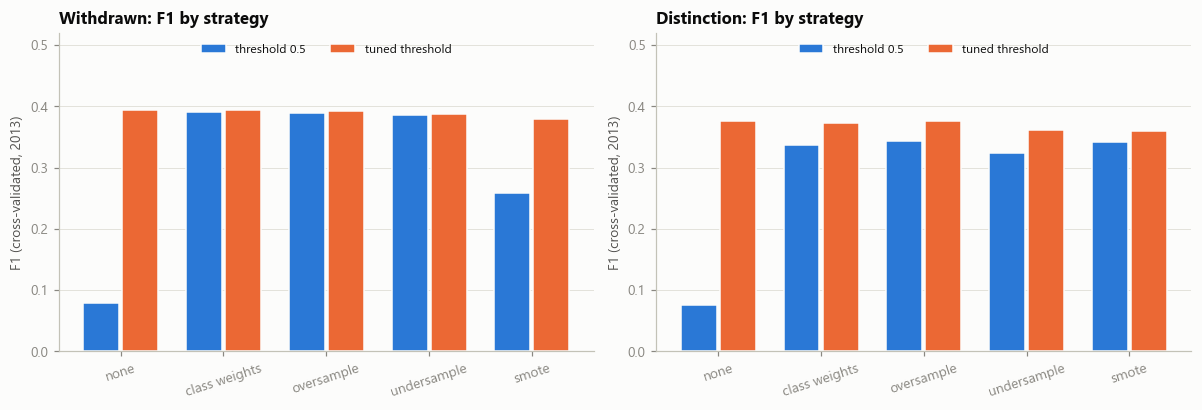

In [4]:
display(imb.set_index(["target", "strategy"])[["test_roc_auc", "test_pr_auc", "test_f1_at_0_5", "test_f1_tuned", "test_mean_pred", "test_prevalence", "test_brier"]])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, tname in zip(axes, ["Withdrawn", "Distinction"]):
    d = imb[imb.target == tname].reset_index(drop=True); x = np.arange(len(d)); w = 0.38
    ax.bar(x - w / 2, d.cv_f1_at_0_5, width=w - 0.03, color=C1, edgecolor=SURFACE, label="threshold 0.5"); ax.bar(x + w / 2, d.cv_f1_tuned, width=w - 0.03, color=C2, edgecolor=SURFACE, label="tuned threshold")
    ax.set_xticks(x, d.strategy, rotation=18); ax.set_ylabel("F1 (cross-validated, 2013)"); ax.set_title(f"{tname}: F1 by strategy"); ax.grid(axis="x", visible=False); ax.set_ylim(0, 0.52); ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper center")
fig.tight_layout(); savefig(fig, "07b_imbalance_f1.png"); plt.show()

**Observed (cross-validation on 2013; the 2014 columns tell the same story).**
- **Ranking is not helped.** ROC-AUC and PR-AUC are the same with and without class weights or oversampling (Withdrawn: 0.706 and 0.335 plain, 0.706 and 0.336 with weights, 0.702 and 0.329 oversampled). Undersampling throws data away (0.699 and 0.314) and **SMOTE hurts** (0.686 and 0.310; on 2014 AUC 0.663 vs 0.696).
- **The default threshold is the problem, and a threshold can fix it.** With no adjustment the model almost never predicts the rare class at a cut-off of 0.5 (F1 of 0.08 for Withdrawn, 0.08 for Distinction). Weights, oversampling and undersampling lift F1 at 0.5 to 0.34 to 0.39, but simply moving the threshold of the *unchanged* model reaches the same F1 (Withdrawn 0.394 against 0.387 to 0.393; Distinction 0.376 against 0.360 to 0.376). On 2014 the tuned plain model scores 0.429 for Withdrawn, the best of all.
- **The rare outcomes are harder.** Even the best F1 is about 0.43 for Withdrawn (AUC 0.70) and 0.40 for Distinction (AUC 0.81), against AUC 0.78 for the main target.
**Why it matters.** The usual fixes shift the decision threshold; they add no information. For triage and ranking, keep the plain model and tune the threshold (or flag a fixed share of students, as in 07a). SMOTE interpolates between students on ordinal and rank features and creates unrealistic cases.

### 1.3 What do the fixes do to the probabilities?

Resampling and class weights change how many positives the model sees, so the predicted probabilities no longer mean what they say. The table below compares the average predicted probability with the real prevalence in 2014.

In [5]:
cal = imb[["target", "strategy", "test_mean_pred", "test_prevalence"]].assign(inflation=lambda d: d.test_mean_pred / d.test_prevalence)
cal.pivot(index="strategy", columns="target", values="inflation").loc[STRATS].rename_axis(columns="predicted / actual prevalence")

predicted / actual prevalence,Distinction,Withdrawn
strategy,,
none,0.758,0.827
class weights,3.033,2.221
oversample,2.839,2.143
undersample,3.213,2.287
smote,1.926,1.527


**Observed.** Resampling and class weights make the predicted probabilities wrong: the average predicted probability is 2.1 to 3.2 times the real prevalence for weights, oversampling and undersampling, and 1.5 to 1.9 times for SMOTE (Brier score for Withdrawn 0.146 plain vs 0.207 with weights). The plain model slightly *under*-predicts (0.76 to 0.83 times) because the rare outcomes became more common in 2014.
**Why it matters.** If a risk has to be read as a probability (for example to decide who to contact), do not resample or reweight, or recalibrate afterwards. Never resample before splitting, because duplicated or synthetic rows would end up on both sides.

## 2. Data leakage

### 2.1 Future information: three leaky features built on purpose

A leak is any feature that would not be available at prediction time (day 28). Three are built from information after day 28 and added to the legitimate model:

- `clicks_28_55`: total clicks on days 28 to 55.
- `late_score_mean`: mean score of assessments submitted on or after day 28.
- `left_by_day_56`: the student has unregistered by day 56.

In [6]:
sv = pd.read_csv(RAW / "studentVle.csv", usecols=["code_module", "code_presentation", "id_student", "date", "sum_click"],
                 dtype={"code_module": "category", "code_presentation": "category", "id_student": "int32", "date": "int16", "sum_click": "int16"})
sv = sv[(sv["date"] >= 28) & (sv["date"] < 56)].astype({"code_module": "object", "code_presentation": "object"})
fut = sv.groupby(KEY).sum_click.sum().rename("clicks_28_55").reset_index()
sa = pd.read_csv(RAW / "studentAssessment.csv", na_values=["?"]); asm = pd.read_csv(RAW / "assessments.csv", na_values=["?"])
late = sa.merge(asm[["id_assessment", "code_module", "code_presentation"]], on="id_assessment")
late = late[(late.date_submitted >= 28) & (late.is_banked == 0)].groupby(KEY).score.mean().rename("late_score_mean").reset_index()
reg = pd.read_csv(RAW / "studentRegistration.csv", na_values=["?"]); reg["left_by_day_56"] = (reg.date_unregistration < 56).astype(int)
def add_leaks(df):
    d = df.merge(fut, on=KEY, how="left").merge(late, on=KEY, how="left").merge(reg[KEY + ["left_by_day_56"]], on=KEY, how="left")
    d["clicks_28_55"] = d.clicks_28_55.fillna(0); d["left_by_day_56"] = d.left_by_day_56.fillna(0); return d
trL, teL = add_leaks(train), add_leaks(test)
assert len(trL) == len(train) and len(teL) == len(test)
LEAKS = ["clicks_28_55", "late_score_mean", "left_by_day_56"]
print({c: f"{trL[c].notna().mean():.0%} non-missing" for c in LEAKS})

def cv_test_auc(num, cat=("code_module",), tr=None, te=None):
    tr = trL if tr is None else tr; te = teL if te is None else te
    oof = np.zeros(len(tr))
    for a, b in folds: oof[b] = pipe_hgb(num, cat).fit(tr.iloc[a][list(num) + list(cat)], tr.target_at_risk.values[a]).predict_proba(tr.iloc[b][list(num) + list(cat)])[:, 1]
    p = pipe_hgb(num, cat).fit(tr[list(num) + list(cat)], tr.target_at_risk.values).predict_proba(te[list(num) + list(cat)])[:, 1]
    return roc_auc_score(tr.target_at_risk, oof), roc_auc_score(te.target_at_risk, p)
base_cv, base_te = cv_test_auc(SEL_NUM)
rows = [dict(model="legitimate features (day 28)", extra="", cv_auc_2013=base_cv, test_auc_2014=base_te)]
for lk in LEAKS:
    a, b = cv_test_auc(SEL_NUM + [lk]); rows.append(dict(model=f"+ {lk}", extra=lk, cv_auc_2013=a, test_auc_2014=b))
a, b = cv_test_auc(SEL_NUM + LEAKS); rows.append(dict(model="+ all three", extra="all", cv_auc_2013=a, test_auc_2014=b))
leak1 = pd.DataFrame(rows).set_index("model"); leak1["inflation_test"] = leak1.test_auc_2014 - leak1.loc["legitimate features (day 28)", "test_auc_2014"]
leak1.to_csv(OUT / "leakage_future_features.csv"); leak1[["cv_auc_2013", "test_auc_2014", "inflation_test"]]

{'clicks_28_55': '100% non-missing', 'late_score_mean': '85% non-missing', 'left_by_day_56': '100% non-missing'}


,cv_auc_2013,test_auc_2014,inflation_test
model,,,
legitimate features (day 28),0.793,0.780,0.000
+ clicks_28_55,0.818,0.807,0.028
+ late_score_mean,0.866,0.859,0.079
+ left_by_day_56,0.803,0.794,0.014
+ all three,0.869,0.864,0.084


**Observed.** Adding information from after day 28 inflates the 2014 test AUC from 0.780 to 0.807 (clicks on days 28 to 55), 0.859 (scores of assessments submitted after day 28) and 0.794 (having left by day 56, an outcome proxy that matters less here because students who left before day 28 are already excluded). With all three: **0.864, an inflation of 0.084**.
**The leak is inside the test data as well**, so the inflated test score looks just like a trustworthy one. A train/test split cannot catch future-information leaks; only a timeline audit can (when does each field become known?).

### 2.2 Split leakage: random rows vs students vs time

In [7]:
pool = pd.concat([train, test], ignore_index=True); ypool = pool.target_at_risk.values; cols = SEL_NUM + SEL_CAT
def kfold_auc(splitter, groups=None):
    oof = np.zeros(len(pool))
    for a, b in splitter.split(pool, ypool, groups) if groups is not None else splitter.split(pool, ypool):
        oof[b] = pipe_hgb(SEL_NUM, SEL_CAT).fit(pool.iloc[a][cols], ypool[a]).predict_proba(pool.iloc[b][cols])[:, 1]
    return roc_auc_score(ypool, oof)
rand_auc = kfold_auc(StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
grp_auc = kfold_auc(GroupKFold(5), pool.id_student.values)
temporal = roc_auc_score(y_te, pipe_hgb(SEL_NUM, SEL_CAT).fit(train[cols], y_tr).predict_proba(test[cols])[:, 1])
split_df = pd.DataFrame({"AUC": [rand_auc, grp_auc, temporal]}, index=["random rows (2013+2014 pooled)", "grouped by student (2013+2014 pooled)", "temporal: train 2013, test 2014 (honest)"])
split_df["optimism_vs_temporal"] = split_df.AUC - temporal; split_df

,AUC,optimism_vs_temporal
random rows (2013+2014 pooled),0.789,0.009
grouped by student (2013+2014 pooled),0.789,0.009
"temporal: train 2013, test 2014 (honest)",0.780,0.000


**Observed.** Pooling both years and splitting rows at random gives AUC 0.789; grouping by student changes nothing (0.789); the honest temporal test gives 0.780. A random split is therefore about 0.009 optimistic for a year-ahead claim. Grouping by student matters little here because only 9% of the 2014 students also appear in 2013.

### 2.3 Target-encoding leakage

A very specific cell (module x region x deprivation band x prior education, thousands of cells with a few students each) is turned into the average outcome of its members. Computed on all rows, each student's own label leaks into their feature; computed out-of-fold it does not.

In [8]:
c_tr = it.categories(train, pd.read_csv(PROC / "oulad_clusters_day28.csv"), it.fit_item_spec(train))
cell = (c_tr.Module + "|" + c_tr.Region + "|" + c_tr.IMDBand.fillna("NA") + "|" + c_tr.EducationFine).values
print(f"{pd.Series(cell).nunique():,} cells for {len(cell):,} students (average {len(cell) / pd.Series(cell).nunique():.1f} students per cell)")
leaky = pd.Series(y_tr).groupby(cell).transform("mean").values                  # includes the student's own label
honest = np.zeros(len(cell)); prior = y_tr.mean()
for a, b in folds:
    m = pd.Series(y_tr[a]).groupby(cell[a]).agg(["sum", "count"]); sm_ = (m["sum"] + 5 * prior) / (m["count"] + 5)       # smoothed, fitted on the training part only
    honest[b] = pd.Series(cell[b]).map(sm_).fillna(prior).values
res = pd.DataFrame({"AUC of this one feature": [roc_auc_score(y_tr, leaky), roc_auc_score(y_tr, honest)]}, index=["encoded on all rows (leaks the label)", "encoded out-of-fold, smoothed (correct)"]); res

1,909 cells for 11,818 students (average 6.2 students per cell)


,AUC of this one feature
encoded on all rows (leaks the label),0.772
"encoded out-of-fold, smoothed (correct)",0.597


**Observed.** Turning 1,909 fine-grained cells (about 6 students per cell) into their average outcome gives a single-feature AUC of 0.772 when the average includes the student's own label, against 0.597 when it is computed out-of-fold and smoothed: the leak is worth 0.175.

### 2.4 Selection leakage: choosing features before cross-validating

Pure noise cannot predict anything. If 300 random features are screened on all rows *before* cross-validation, the screening has already seen the labels and the CV score looks real.

In [9]:
rng = np.random.RandomState(RANDOM_STATE); n = 600
idx = rng.choice(len(train), n, replace=False); ys = y_tr[idx]; Xn = rng.normal(size=(n, 300))
def top_k(X, y, k=10): return np.argsort(-np.abs([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])]))[:k]
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
leaky_cols = top_k(Xn, ys); oof_leaky = np.zeros(n); oof_ok = np.zeros(n)
for a, b in skf.split(Xn, ys):
    oof_leaky[b] = LogisticRegression(max_iter=2000).fit(Xn[a][:, leaky_cols], ys[a]).predict_proba(Xn[b][:, leaky_cols])[:, 1]       # columns chosen with ALL labels
    cols_in = top_k(Xn[a], ys[a]); oof_ok[b] = LogisticRegression(max_iter=2000).fit(Xn[a][:, cols_in], ys[a]).predict_proba(Xn[b][:, cols_in])[:, 1]   # chosen inside the training part
pd.DataFrame({"CV AUC on pure noise": [roc_auc_score(ys, oof_leaky), roc_auc_score(ys, oof_ok)]}, index=["screening done before cross-validation (leak)", "screening inside each training fold (correct)"])

,CV AUC on pure noise
screening done before cross-validation (leak),0.638
screening inside each training fold (correct),0.488


**Observed.** 300 pure-noise features and 600 students: screening the features on all the labels *before* cross-validation produces a cross-validated AUC of 0.64 for something that predicts nothing; screening inside each training fold gives 0.49, chance level. The inflation is 0.15.

### 2.5 Preprocessing leakage: scaling and imputing on the test data too

In [10]:
Xa, Xb = train[SEL_NUM].values, test[SEL_NUM].values
def lr_auc(fit_on):
    imp = SimpleImputer(strategy="median").fit(fit_on); sc = StandardScaler().fit(imp.transform(fit_on))
    f = lambda X: sc.transform(imp.transform(X))
    return roc_auc_score(y_te, LogisticRegression(max_iter=3000).fit(f(Xa), y_tr).predict_proba(f(Xb))[:, 1])
pd.DataFrame({"2014 AUC": [lr_auc(Xa), lr_auc(np.vstack([Xa, Xb]))]}, index=["scaler and imputer fitted on 2013 only (correct)", "scaler and imputer fitted on 2013 + 2014 (leak)"])

,2014 AUC
scaler and imputer fitted on 2013 only (correct),0.771
scaler and imputer fitted on 2013 + 2014 (leak),0.771


**Observed.** Fitting the scaler and imputer on both years changes nothing measurable here (0.771 either way): with almost 12,000 rows the training median and standard deviation are stable. The practice costs nothing and prevents the leak in small data, so it stays.

### 2.6 Leakage ledger

In [11]:
ledger = pd.DataFrame([
    ("Future information (clicks after day 28)", leak1.loc["+ clicks_28_55", "test_auc_2014"] - leak1.loc["legitimate features (day 28)", "test_auc_2014"], "No: the leak is in the test data too", "Timeline audit: record when each field becomes known"),
    ("Future information (late scores)", leak1.loc["+ late_score_mean", "test_auc_2014"] - leak1.loc["legitimate features (day 28)", "test_auc_2014"], "No", "Cut every source table at the prediction day"),
    ("Future information (left by day 56)", leak1.loc["+ left_by_day_56", "test_auc_2014"] - leak1.loc["legitimate features (day 28)", "test_auc_2014"], "No", "Never use outcome-derived fields (the label in disguise)"),
    ("Random-row split instead of temporal", split_df.iloc[0, 0] - temporal, "Partly", "Split by time and by student"),
    ("Target encoding on all rows", res.iloc[0, 0] - res.iloc[1, 0], "No (inside the training data)", "Encode out-of-fold with smoothing"),
    ("Feature screening before CV (noise)", roc_auc_score(ys, oof_leaky) - roc_auc_score(ys, oof_ok), "No", "Put every fitted step inside the CV pipeline"),
], columns=["leak", "AUC inflation", "caught by a train/test split?", "prevention"]).set_index("leak")
ledger.to_csv(OUT / "leakage_ledger.csv"); ledger

,AUC inflation,caught by a train/test split?,prevention
leak,,,
Future information (clicks after day 28),0.028,No: the leak is in the test data too,Timeline audit: record when each field becomes known
Future information (late scores),0.079,No,Cut every source table at the prediction day
Future information (left by day 56),0.014,No,Never use outcome-derived fields (the label in disguise)
Random-row split instead of temporal,0.009,Partly,Split by time and by student
Target encoding on all rows,0.175,No (inside the training data),Encode out-of-fold with smoothing
Feature screening before CV (noise),0.149,No,Put every fitted step inside the CV pipeline


**Reading the ledger.** The leaks that matter most are the ones nothing in the usual workflow flags: future information (up to +0.08 AUC) and encoding or screening the labels before splitting (+0.15 to +0.18 in the small-sample or fine-cell cases). The cure is procedural: a written timeline of when every field becomes known, and every fitted step inside the cross-validation pipeline.

## 3. Data drift

### 3.1 Labels and module mix

In [12]:
mix = pd.concat([train.code_module.value_counts(normalize=True).rename("share 2013"), test.code_module.value_counts(normalize=True).rename("share 2014")], axis=1).fillna(0).sort_index()
mix["at-risk rate 2013"] = train.groupby("code_module").target_at_risk.mean(); mix["at-risk rate 2014"] = test.groupby("code_module").target_at_risk.mean()
mix["rate change"] = mix["at-risk rate 2014"] - mix["at-risk rate 2013"]; display(mix)
res4 = pd.concat([train.target_final_result.value_counts(normalize=True).rename("2013"), test.target_final_result.value_counts(normalize=True).rename("2014")], axis=1)
res4["change"] = res4["2014"] - res4["2013"]; display(res4)

,share 2013,share 2014,at-risk rate 2013,at-risk rate 2014,rate change
code_module,,,,,
AAA,0.031,0.022,0.249,0.273,0.024
BBB,0.285,0.195,0.443,0.388,-0.055
CCC,0.000,0.224,NaN,0.524,NaN
DDD,0.236,0.158,0.521,0.490,-0.031
EEE,0.078,0.103,0.343,0.360,0.017
FFF,0.291,0.201,0.454,0.440,-0.014
GGG,0.078,0.096,0.359,0.391,0.032


,2013,2014,change
target_final_result,,,
Pass,0.465,0.436,-0.028
Fail,0.274,0.242,-0.032
Withdrawn,0.170,0.198,0.027
Distinction,0.091,0.124,0.033


**Observed.** The overall at-risk rate is stable (44.4% to 44.0%), but the outcomes behind it moved: Withdrawn +2.7 points, Distinction +3.3, Fail -3.2, Pass -2.8. Within modules the at-risk rate moved by up to 5.5 points (BBB -5.5, DDD -3.1, GGG +3.2, AAA +2.4), and the module mix changed completely: CCC went from 0% to 22.4% of the students and BBB, DDD and FFF each lost 8 to 9 points of share.

### 3.2 Input drift: population stability index and Kolmogorov-Smirnov distance

PSI compares the share of students in each bin (bins fixed on 2013) between the two years; a value below 0.1 is usually read as no meaningful shift, 0.1 to 0.25 as moderate and above 0.25 as major.

In [13]:
def psi(a, b, bins=10):
    a, b = pd.Series(a), pd.Series(b)
    if a.nunique(dropna=True) <= 12 or a.dtype == object:
        cats_ = sorted(set(a.dropna().unique()) | set(b.dropna().unique()), key=str)
        pa = np.array([(a == c).mean() for c in cats_] + [a.isna().mean()]); pb = np.array([(b == c).mean() for c in cats_] + [b.isna().mean()])
    else:
        edges = np.unique(np.quantile(a.dropna(), np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
        pa = np.append(np.histogram(a.dropna(), edges)[0] / len(a), a.isna().mean()); pb = np.append(np.histogram(b.dropna(), edges)[0] / len(b), b.isna().mean())
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None); return float(np.sum((pb - pa) * np.log(pb / pa)))
rows = []
for c in SEL_NUM + SEL_CAT:
    ks = stats.ks_2samp(train[c].dropna(), test[c].dropna()).statistic if c in SEL_NUM else np.nan
    rows.append(dict(feature=c, psi=psi(train[c], test[c]), ks=ks))
drift = pd.DataFrame(rows).set_index("feature").sort_values("psi", ascending=False)
drift["verdict"] = np.where(drift.psi >= 0.25, "major", np.where(drift.psi >= 0.10, "moderate", "none"))
drift.to_csv(OUT / "feature_drift_2013_vs_2014.csv"); drift

,psi,ks,verdict
feature,,,
module_presentation_length,16.090,0.379,major
code_module,1.839,NaN,major
days_before_due_mean,0.379,0.226,major
share_subpage,0.154,0.173,moderate
score_pct_mean,0.110,0.039,moderate
n_submitted_after_due,0.069,0.093,none
submit_rate_early,0.061,0.014,none
credits_capped,0.053,0.071,none
log_clicks_total,0.017,0.045,none


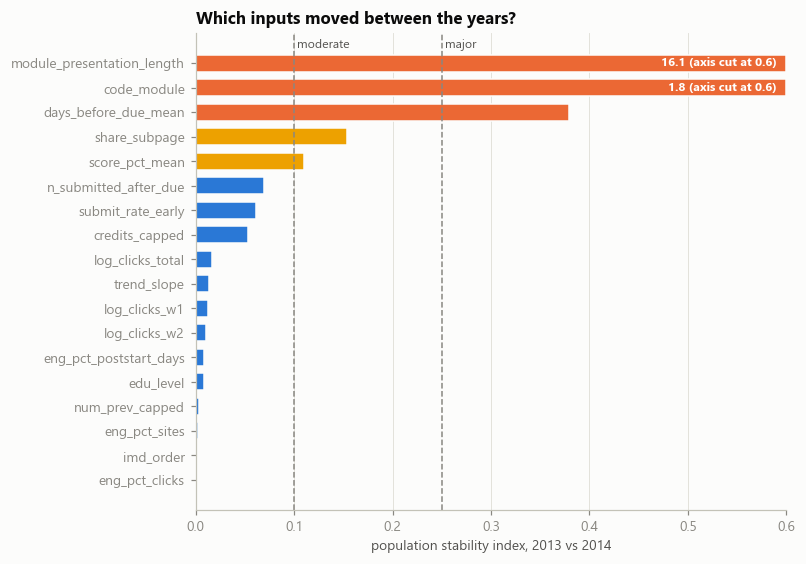

In [14]:
t = drift.iloc[::-1]; fig, ax = plt.subplots(figsize=(7.4, 5.2))
colors = [C2 if v >= 0.25 else (C4 if v >= 0.10 else C1) for v in t.psi]
CLIP = 0.6
ax.barh(t.index, t.psi.clip(upper=CLIP), color=colors, edgecolor=SURFACE, height=0.7); ax.axvline(0.10, color=MUTED, linestyle="--", linewidth=1); ax.axvline(0.25, color=MUTED, linestyle="--", linewidth=1)
for yi, v in enumerate(t.psi):
    if v > CLIP: ax.text(CLIP - 0.01, yi, f"{v:.1f} (axis cut at {CLIP})", ha="right", va="center", color="#ffffff", fontsize=8, fontweight="bold")
ax.text(0.103, len(t) - 0.35, "moderate", color=INK2, fontsize=8); ax.text(0.253, len(t) - 0.35, "major", color=INK2, fontsize=8)
ax.set_xlim(0, CLIP); ax.set_xlabel("population stability index, 2013 vs 2014"); ax.grid(axis="y", visible=False); ax.set_title("Which inputs moved between the years?")
fig.tight_layout(); savefig(fig, "07b_feature_psi.png"); plt.show()

**Observed.** Behavioural engagement is stable (PSI of 0.02 or less for clicks, trend, active days and the engagement ranks). The drift is in the structure of the courses:
- `module_presentation_length` (PSI 16.1) is the extreme case: its values are 240, 261 and 268 days in 2013 and 234, 241, 262 and 269 in 2014, with **no overlap**. It identifies the presentation, not the student.
- `code_module` (PSI 1.8), because of CCC.
- `days_before_due_mean` (PSI 0.38; mean 12.9 to 10.4 days) is heavy-tailed (some values reach 240 days when a student submits early for an assessment due near the end of the course), so the mean is dominated by a few cases.
- `share_subpage` (0.15) and `score_pct_mean` (0.11) are moderate; the latter moved because 10.6% of the 2014 students have no ordinary score (the 100-or-1 assessment).
**Why it matters.** Two of the selected features are fragile: one is a presentation fingerprint and one is sensitive to outliers. Both are examined in section 3.4b.

### 3.3 Adversarial validation: can a model tell 2013 from 2014?

If a classifier separates the two years from the features alone, the inputs have shifted. Its permutation importance says which inputs give the years away.

In [15]:
pool = pd.concat([train.assign(_y=0), test.assign(_y=1)], ignore_index=True)
def adv_auc(num, cat, data):
    oof = np.zeros(len(data)); skf2 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
    for a, b in skf2.split(data, data._y): oof[b] = pipe_hgb(num, cat).fit(data.iloc[a][list(num) + list(cat)], data._y.values[a]).predict_proba(data.iloc[b][list(num) + list(cat)])[:, 1]
    return roc_auc_score(data._y, oof)
no_mod = [c for c in SEL_NUM if c != "module_presentation_length"]
RANKS = [c for c in no_mod if c.startswith("eng_pct") or c == "score_pct_mean"]      # percentile ranks inside a module-presentation
no_rank = [c for c in no_mod if c not in RANKS]
noccc = pool[pool.code_module != "CCC"]
adv = pd.DataFrame({"AUC (0.5 = years indistinguishable)": [adv_auc(SEL_NUM, SEL_CAT, pool), adv_auc(no_mod, [], pool), adv_auc(no_mod, [], noccc), adv_auc(no_rank, [], pool), adv_auc(no_rank, [], noccc)]},
                   index=["all selected features, including the module", "no module information (no module label, no course length)", "same, with module CCC removed from 2014",
                          "same as the second row, and without the percentile-rank features", "same, without ranks and with CCC removed from 2014"])
display(adv)
m_adv = pipe_hgb(no_mod, []).fit(pool[no_mod], pool._y)
pi = permutation_importance(m_adv, pool[no_mod], pool._y, scoring="roc_auc", n_repeats=3, random_state=RANDOM_STATE)
display(pd.Series(pi.importances_mean, index=no_mod).sort_values(ascending=False).head(6).to_frame("drop in AUC when shuffled"))

,AUC (0.5 = years indistinguishable)
"all selected features, including the module",1.000
"no module information (no module label, no course length)",0.886
"same, with module CCC removed from 2014",0.891
"same as the second row, and without the percentile-rank features",0.711
"same, without ranks and with CCC removed from 2014",0.648


,drop in AUC when shuffled
score_pct_mean,0.183
submit_rate_early,0.127
eng_pct_poststart_days,0.116
days_before_due_mean,0.089
credits_capped,0.039
log_clicks_total,0.036


**Observed.** A classifier separates 2013 from 2014 perfectly (AUC 1.000) as soon as `module_presentation_length` is allowed, and still at 0.89 without that feature and without the module label (0.89 again with CCC removed). The features that give the years away are the percentile-rank features (`score_pct_mean`, `eng_pct_poststart_days`) and `submit_rate_early`.
**But much of this is a measurement artefact.** A percentile rank inside a group of n students can only take values on a grid of width 1/n, and n differs between presentations, so the exact rank values reveal the presentation whatever the students did. Without the rank features the AUC falls to **0.71**, and to **0.65** once CCC is removed; that is the shift that is really in the behaviour and assessment data.
**Why it matters.** Adversarial validation overstates drift when features encode group size. The real shift between the years is moderate, and the engagement, scores and background features still describe comparable students.

Is the shift only module mix? The same adversarial test inside each module that exists in both years, with and without the percentile-rank features. The ranks are suspect: a rank inside a group of n students can only take values on a grid of width 1/n, and n differs between presentations, so the exact values can reveal the presentation whatever the students did.

In [16]:
rows = []
for m in sorted(set(train.code_module) & set(test.code_module)):
    d = pool[pool.code_module == m]
    rows.append(dict(module=m, n_2013=int((d._y == 0).sum()), n_2014=int((d._y == 1).sum()), auc_with_rank_features=adv_auc(no_mod, [], d), auc_without_rank_features=adv_auc(no_rank, [], d)))
adv_mod = pd.DataFrame(rows).set_index("module"); adv_mod

,n_2013,n_2014,auc_with_rank_features,auc_without_rank_features
module,,,,
AAA,370,348,0.676,0.574
BBB,3366,3069,0.994,0.668
DDD,2794,2493,0.967,0.802
EEE,927,1626,0.979,0.630
FFF,3437,3162,0.986,0.686
GGG,924,1514,0.995,0.574


**Observed.** Inside a single module the years look perfectly separable when the rank features are included (AUC 0.97 to 0.995 for BBB, DDD, EEE, FFF and GGG; 0.68 for the small AAA), which is the grid artefact described above. Without the rank features the separation is much smaller and varies by module: 0.57 (AAA and GGG), 0.63 (EEE), 0.67 (BBB), 0.69 (FFF) and **0.80 (DDD)**.
**Why it matters.** There is real but moderate within-module shift (the course structure, deadlines and assessments change from one presentation to the next), largest in DDD. What matters for use is whether the *relationship* with the outcome moved, which the next test addresses.

### 3.4 Concept drift: has the relationship between inputs and outcome changed?

The 2013 model is compared with a model that has seen 2014 (5-fold cross-validation inside 2014, grouped by student), on the same 2014 students.

In [17]:
pred14 = pd.read_csv(PROC / "oulad_predictions_2014.csv")
assert (pred14[KEY].values == test[KEY].values).all()
oof14 = np.zeros(len(test))
for a, b in GroupKFold(5).split(test, groups=test.id_student):
    oof14[b] = pipe_hgb(SEL_NUM, SEL_CAT).fit(test.iloc[a][SEL_NUM + SEL_CAT], y_te[a]).predict_proba(test.iloc[b][SEL_NUM + SEL_CAT])[:, 1]
rows = [dict(segment="all of 2014", auc_2013_model=roc_auc_score(y_te, pred14.p_hgb), auc_model_that_saw_2014=roc_auc_score(y_te, oof14))]
for m in sorted(test.code_module.unique()):
    mk = (test.code_module == m).values; rows.append(dict(segment=f"module {m}", auc_2013_model=roc_auc_score(y_te[mk], pred14.p_hgb[mk]), auc_model_that_saw_2014=roc_auc_score(y_te[mk], oof14[mk])))
cd = pd.DataFrame(rows).set_index("segment"); cd["retraining_gain"] = cd.auc_model_that_saw_2014 - cd.auc_2013_model; display(cd)

# coefficient stability: standardised logistic coefficients fitted separately on each year
def std_coefs(df):
    X = df[no_mod]; imp = SimpleImputer(strategy="median").fit(X); sc = StandardScaler().fit(imp.transform(X))
    return pd.Series(LogisticRegression(max_iter=3000, C=0.1).fit(sc.transform(imp.transform(X)), df.target_at_risk).coef_[0], index=no_mod)
co = pd.DataFrame({"2013": std_coefs(train), "2014": std_coefs(test)}); co["abs_difference"] = (co["2014"] - co["2013"]).abs()
print(f"Spearman correlation of the standardised coefficients between the years: {stats.spearmanr(co['2013'], co['2014'])[0]:.3f}")
display(co.sort_values("abs_difference", ascending=False).head(6))

,auc_2013_model,auc_model_that_saw_2014,retraining_gain
segment,,,
all of 2014,0.780,0.781,0.002
module AAA,0.704,0.697,-0.006
module BBB,0.736,0.731,-0.005
module CCC,0.810,0.814,0.004
module DDD,0.800,0.804,0.004
module EEE,0.775,0.774,-0.001
module FFF,0.788,0.791,0.004
module GGG,0.688,0.679,-0.009


Spearman correlation of the standardised coefficients between the years: 0.982


,2013,2014,abs_difference
n_submitted_after_due,0.170,0.278,0.108
log_clicks_w1,0.054,-0.039,0.093
submit_rate_early,-0.582,-0.497,0.085
log_clicks_total,0.064,-0.017,0.081
log_clicks_w2,-0.101,-0.030,0.071
eng_pct_clicks,0.083,0.021,0.062


**Observed.** The 2013 model does as well on 2014 as a model that has seen 2014 data (AUC 0.780 against 0.781; per module from -0.009 to +0.004), and the standardised coefficients fitted separately on each year correlate at 0.98. The largest changes are modest (`n_submitted_after_due` 0.17 to 0.28, `submit_rate_early` -0.58 to -0.50).
**Why it matters.** This is **covariate shift without concept drift**: the inputs moved (module mix, deadlines), but how they relate to the outcome did not. Retraining on 2014 would add almost nothing right now, and the model can be trusted on the next year as long as inputs stay inside the ranges it knows.

### 3.4b Fragile features: sensitivity of the 2014 result (reported, not used to choose)

Two selected features look fragile: `module_presentation_length` (values never overlap between the years) and `days_before_due_mean` (heavy-tailed, major drift). The primary model of notebook 07a is **not** changed; this shows how much it depends on them.

In [18]:
def with_cap(df): d = df.copy(); d["days_before_due_mean"] = d.days_before_due_mean.clip(-10, 30); return d
trC, teC = with_cap(train), with_cap(test)
def fit_eval(num, cat, tr, te):
    oof = np.zeros(len(tr))
    for a, b in folds: oof[b] = pipe_hgb(num, cat).fit(tr.iloc[a][list(num) + list(cat)], tr.target_at_risk.values[a]).predict_proba(tr.iloc[b][list(num) + list(cat)])[:, 1]
    p = pipe_hgb(num, cat).fit(tr[list(num) + list(cat)], tr.target_at_risk.values).predict_proba(te[list(num) + list(cat)])[:, 1]
    return roc_auc_score(tr.target_at_risk, oof), roc_auc_score(te.target_at_risk, p), p
v1 = fit_eval(SEL_NUM, SEL_CAT, train, test)
v2 = fit_eval(no_mod, SEL_CAT, train, test)
v3 = fit_eval(no_mod, SEL_CAT, trC, teC)
v4 = fit_eval(no_mod, [], trC, teC)
fragile = pd.DataFrame({"cv_auc_2013": [v[0] for v in (v1, v2, v3, v4)], "test_auc_2014": [v[1] for v in (v1, v2, v3, v4)]},
                       index=["as used in 07a (18 features)", "without module_presentation_length", "also with days_before_due_mean capped at 30 days", "also without the module label (no module information at all)"])
mk_ccc = (test.code_module == "CCC").values
fragile["test_auc_module_CCC"] = [roc_auc_score(y_te[mk_ccc], v[2][mk_ccc]) for v in (v1, v2, v3, v4)]
fragile.to_csv(OUT / "drift_fragile_feature_sensitivity.csv"); fragile

,cv_auc_2013,test_auc_2014,test_auc_module_CCC
as used in 07a (18 features),0.793,0.780,0.810
without module_presentation_length,0.793,0.779,0.810
also with days_before_due_mean capped at 30 days,0.792,0.779,0.809
also without the module label (no module information at all),0.789,0.776,0.810


**Observed (2014 AUC).** As used in 07a: 0.780. Without `module_presentation_length`: 0.779. Also capping `days_before_due_mean` at 30 days: 0.779. Also dropping the module label so that the model has no module information at all: 0.776. For the unseen module CCC the AUC is 0.810, 0.810, 0.809 and 0.810.
**Why it matters.** The model does not depend on either fragile feature, nor even on knowing which module a student is in: with no module information it loses only 0.004 AUC and predicts the unseen module just as well. That is the payoff of the module-relative features.
**Why it matters / recommendation.** The deployed model should not contain `module_presentation_length` (the reason is a priori: its values cannot generalise, and the sensitivity check shows no loss) and should cap `days_before_due_mean` at 30 days. These are recommendations for the next version; the 07a results were produced with the original 18 features and are not changed.

### 3.5 A concrete drift event: the 100-or-1 assessment

The old score feature (`mean_score_early`, a raw average that includes the 100-or-1 coded assessment) is compared with the rank-based feature used in the final model, on the 2014 students who are affected.

In [19]:
old_cols = [c if c != "score_pct_mean" else "mean_score_early" for c in SEL_NUM]
m_old = pipe_hgb(old_cols, SEL_CAT).fit(train[old_cols + SEL_CAT], y_tr); p_old = m_old.predict_proba(test[old_cols + SEL_CAT])[:, 1]
m_new = pipe_hgb(SEL_NUM, SEL_CAT).fit(train[SEL_NUM + SEL_CAT], y_tr); p_new = m_new.predict_proba(test[SEL_NUM + SEL_CAT])[:, 1]
aff = (test.n_binary_submitted > 0).values
rows = []
for nm, mk in [("all 2014 students", np.ones(len(test), bool)), ("affected students (binary-coded early submission)", aff), ("not affected", ~aff)]:
    rows.append(dict(group=nm, n=int(mk.sum()), observed=y_te[mk].mean(), pred_old_feature=p_old[mk].mean(), pred_rank_feature=p_new[mk].mean(),
                     auc_old=roc_auc_score(y_te[mk], p_old[mk]), auc_rank=roc_auc_score(y_te[mk], p_new[mk])))
art = pd.DataFrame(rows).set_index("group"); art.to_csv(OUT / "drift_artefact_score_feature.csv"); art

,n,observed,pred_old_feature,pred_rank_feature,auc_old,auc_rank
group,,,,,,
all 2014 students,15735,0.440,0.461,0.443,0.764,0.780
affected students (binary-coded early submission),1674,0.319,0.465,0.336,0.588,0.662
not affected,14061,0.454,0.460,0.455,0.791,0.788


**Observed.** For the 1,674 affected 2014 students (10.6%), the observed at-risk rate is 31.9%. The model with the old raw-score feature predicts 46.5% (an over-prediction of 14.6 points) and has an AUC of only 0.588 for them; the rank-based feature predicts 33.6% and reaches 0.662. Over all of 2014 the AUC is 0.764 with the old feature and 0.780 with the rank feature; for unaffected students there is no difference (0.791 and 0.788).
**Why it matters.** Without the fix of notebook 04 this would have appeared as a mysterious 0.016 drop in test performance (0.074 for the affected students), caused by a coding change in one assessment. It is the kind of event that feature-level monitoring should catch.

### 3.6 Score drift and monitoring plan

In [20]:
oof13 = np.zeros(len(train))
for a, b in folds: oof13[b] = pipe_hgb(SEL_NUM, SEL_CAT).fit(train.iloc[a][SEL_NUM + SEL_CAT], y_tr[a]).predict_proba(train.iloc[b][SEL_NUM + SEL_CAT])[:, 1]
print(f"PSI of the predicted risk score (out-of-fold 2013 vs 2014): {psi(pd.Series(oof13), pd.Series(pred14.p_hgb.values)):.3f}")
print(f"mean predicted risk: 2013 {oof13.mean():.3f} | 2014 {pred14.p_hgb.mean():.3f} | observed 2014 {y_te.mean():.3f}")
monitor = pd.DataFrame([
    ("Input drift", "PSI of each model input against the training year", "weekly during a presentation", "0.10 moderate, 0.25 major", "Inspect the feature and the upstream system; if major, review before trusting alerts"),
    ("Score drift", "PSI of the predicted-risk distribution", "weekly", "above 0.10", "Check module mix and data feeds"),
    ("Missing data", "share missing for each input, per module", "weekly", "twice the training-year share", "Pipeline fault or a coding change (like the 100-or-1 assessment)"),
    ("New categories", "unseen modules, assessment codes, score ranges", "each new presentation", "any", "Validate definitions before scoring"),
    ("Calibration", "mean predicted risk against observed risk, by module", "when outcomes arrive (end of presentation)", "gap above 3 points", "Recalibrate (intercept shift) or retrain"),
    ("Performance", "AUC and recall at the flagged share, overall and per group", "end of each presentation", "AUC down more than 0.03, or any group recall gap up more than 0.05", "Retrain on the latest complete years"),
], columns=["monitor", "what is measured", "how often", "alert level", "action"]).set_index("monitor")
monitor.to_csv(OUT / "monitoring_plan.csv"); monitor

PSI of the predicted risk score (out-of-fold 2013 vs 2014): 0.014
mean predicted risk: 2013 0.444 | 2014 0.443 | observed 2014 0.440


,what is measured,how often,alert level,action
monitor,,,,
Input drift,PSI of each model input against the training year,weekly during a presentation,"0.10 moderate, 0.25 major","Inspect the feature and the upstream system; if major, review before trusting alerts"
Score drift,PSI of the predicted-risk distribution,weekly,above 0.10,Check module mix and data feeds
Missing data,"share missing for each input, per module",weekly,twice the training-year share,Pipeline fault or a coding change (like the 100-or-1 assessment)
New categories,"unseen modules, assessment codes, score ranges",each new presentation,any,Validate definitions before scoring
Calibration,"mean predicted risk against observed risk, by module",when outcomes arrive (end of presentation),gap above 3 points,Recalibrate (intercept shift) or retrain
Performance,"AUC and recall at the flagged share, overall and per group",end of each presentation,"AUC down more than 0.03, or any group recall gap up more than 0.05",Retrain on the latest complete years


**Observed.** The predicted-risk score itself barely moved: PSI 0.014, with a mean of 44.4% in 2013 and 44.3% in 2014 (observed 44.0%). Monitoring the output alone would have missed the module change, the coding artefact and the two fragile features; it takes input-level and per-module monitoring.

## 4. Synthesis

**Class imbalance.** The main target is balanced, but Withdrawn (17% to 20%) and Distinction (9% to 12%) are not, and they drifted. Reweighting and resampling add no ranking information, wreck the probabilities (2 to 3 times too high) and SMOTE hurts; tuning the threshold on the plain model matches or beats all of them. Rare outcomes remain hard (best F1 of 0.43 and 0.40).

**Leakage.** Future information inflates the test AUC by up to 0.084 and is invisible to a train/test split. Random splits are about 0.009 optimistic, target encoding on all rows 0.18, screening before cross-validation 0.15 (in a small noise example). Preprocessing leakage was harmless here. Every leak is prevented by a written timeline and by keeping fitted steps inside the cross-validation pipeline.

**Drift.** Inputs moved (module mix, deadline structure, a coding change) but the relationship with the outcome did not (retraining gain 0.002, coefficient correlation 0.98), so the model transfers. Adversarial validation first suggested a huge shift (AUC 0.89 to 1.00) but most of it came from features that encode group size (rank grids, course length); without them the real shift is moderate (AUC 0.71, and 0.65 without CCC). Two selected features are fragile (`module_presentation_length`, which never overlaps between years, and the heavy-tailed `days_before_due_mean`) but removing them costs about 0.001 AUC, and the old raw-score feature would have cost 0.016 AUC overall and 0.074 for the affected students.

**What to do.** Use the plain model with a tuned threshold or a fixed flagged share; drop `module_presentation_length` and cap `days_before_due_mean` in the next version (no accuracy cost); read adversarial-validation alarms with the rank features removed; run the monitoring plan above, per module; and retrain on the latest complete years when the AUC falls by more than 0.03 or a group's recall gap widens by more than 0.05.